# Reworking Code

I'm stuck. I need to completely rework some things.

Gap = 0.5mm

Bundle = 3mm

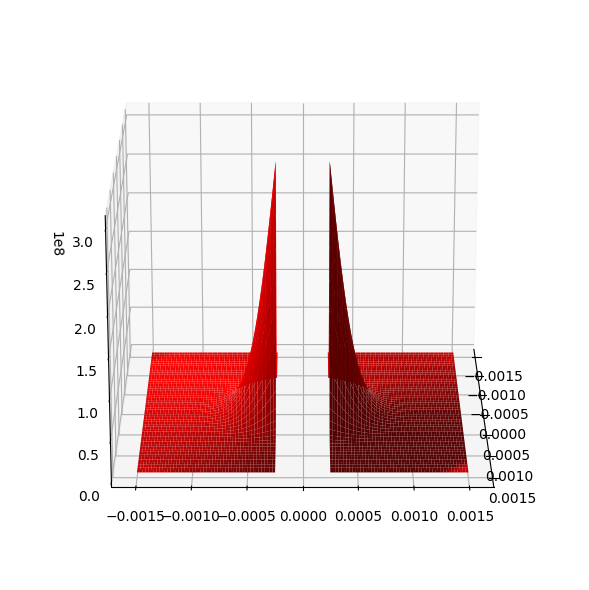

Calculated Integrated Power: 	3.173e+01 W
Calculated Integrated Power: 	3.173e+01 W
Difference of displaced beam: 	0.000e+00 W


Bad pipe message: %s [b'\xd0\x14\x861\xa9W\x80\xcf\xfd\x1a\xf8*\xac\xcc:\xbb\xd4\xbb\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00', b"\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4\x00\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01\x13\x02\x13\x03\x13\x04\x13\x05\xc0\x01\xc0\x02\xc0\x03\xc0\x04\xc0\x05\xc0\x06\xc0\x07\xc0\x08\xc0\t\xc0\n\xc0\x0b\xc0\x0c\xc0\r\xc0\x0e\xc0\x0f\xc0\x10\xc0\x11\xc0\x12\xc0\x13\xc0\x14\xc0\x15\xc0\x16\xc0\x17\xc0\x18\xc0\x19\xc0#\xc0$\xc0%

In [4]:
import jax
import jax.numpy as jnp
from jax import jit
from quadax import quadgk
import matplotlib.pyplot as plt
from laser import jax_hermite

def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    
    norm_factor = (2.0 / (jnp.pi * w**2))**0.25
    field_x = norm_factor * norm_n * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w) * jnp.exp(-(x - mux)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_x**2)

def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = norm_factor * norm_m * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w) * jnp.exp(-(y - muy)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_y ** 2)

def x_integ(bounds, mode, waist, w, P_total, mux=0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ

def y_integ(bounds, mode, waist, w, P_total, muy=0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ

mode = jnp.array([0, 0], dtype=jnp.int32)
waist = 0.5e-3
z = 0
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 1064e-9), 2))
targ_power = 200.0

r = 10 * w
gap = 1e-3
mux = 0
muy = 0


fig = plt.figure(figsize = (12, 6))
ax = fig.add_subplot(111, projection = "3d")
x = jnp.linspace(-3 * w, 3 * w, 1000)
lim = 0.5e-3 / 2
y = jnp.linspace(lim, 3 * w, 1000)
ax.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode, waist, w, targ_power, muy), color = "r", zorder = 100)
y = -y[::-1]
ax.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode, waist, w, targ_power, muy), color = "r", zorder = 100)

ax.view_init(elev=20, azim=0, roll=0)
plt.tight_layout()
plt.show()

power_x = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)
power_y = y_integ(jnp.array([-r, -lim]), mode, waist, w, targ_power, muy=muy)
total_calculated_power1 = power_x * power_y

print(f"Calculated Integrated Power: \t{total_calculated_power1:.3e} W")

power_x = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)
power_y = y_integ(jnp.array([lim, r]), mode, waist, w, targ_power, muy=muy)
total_calculated_power2 = power_x * power_y

print(f"Calculated Integrated Power: \t{total_calculated_power2:.3e} W")
print(f"Difference of displaced beam: \t{total_calculated_power2 - total_calculated_power1:.3e} W")

In [2]:
import matplotlib.animation as animation
import jax
import jax.numpy as jnp
from jax import jit
from quadax import quadgk
import matplotlib.pyplot as plt
from laser import jax_hermite

mux = jnp.zeros(1000)
amp = 1e-3
muy = amp * jnp.sin(jnp.linspace(0, 10 * jnp.pi, 1000))
x = jnp.linspace(-3 * w, 3 * w, 1000)
y1 = jnp.linspace(lim, 3 * w, 1000)
y2 = -y1[::-1]
fig = plt.figure(figsize = (12, 6))
ax = fig.add_subplot(111, projection = "3d")

def ani(i):
    ax.clear()
    mesh1 = ax.plot_surface(x[jnp.newaxis, :], y1[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode, waist, w, targ_power, mux[i]) * I_y(y1[:, jnp.newaxis], mode, waist, w, targ_power, muy[i]))
    mesh2 = ax.plot_surface(x[jnp.newaxis, :], y2[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode, waist, w, targ_power, mux[i]) * I_y(y2[:, jnp.newaxis], mode, waist, w, targ_power, muy[i]))
    return mesh1, mesh2

a = animation.FuncAnimation(
    fig = fig, 
    func=ani, 
    frames=range(0, len(mux), 20), 
    interval=30, 
    blit=False
)
plt.show()

NameError: name 'w' is not defined

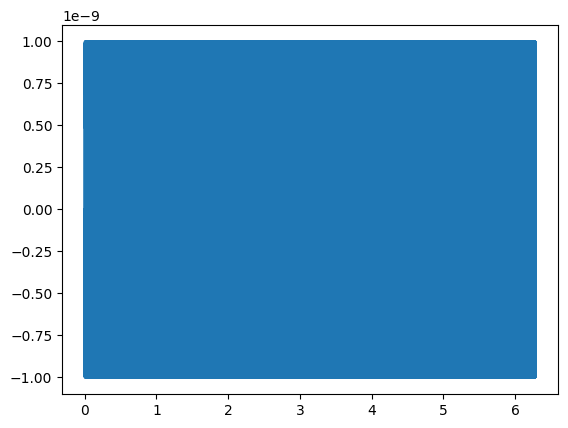

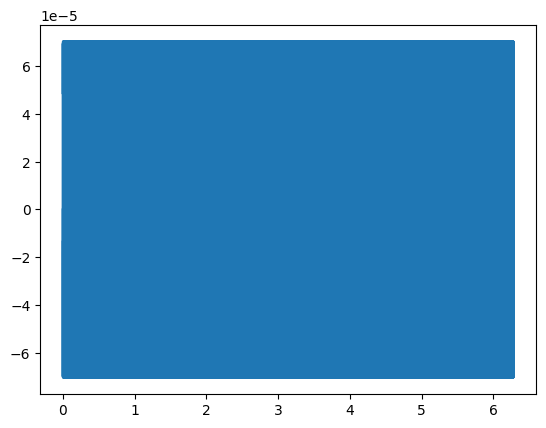

In [318]:
mux = 0
amp = 1e-9
muy = amp * jnp.sin((108000 * 2 * jnp.pi) * jnp.linspace(0, 10 * jnp.pi, 100000))
mode = jnp.array([0, 1], dtype = jnp.int32)
waist = 1e-3
z = 0
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 1064e-9), 2))
targ_power = 200.0

r = 3e-3
gap = 1e-3 / 2
def diff(muy):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = muy) - x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = muy)

plt.plot(jnp.linspace(0, 2 * jnp.pi, 100000), muy)
plt.show()

d = jax.vmap(diff)(muy)
plt.plot(jnp.linspace(0, 2 * jnp.pi, 100000), d)

In [322]:
def diff(muy, r, mode, waist, w, targ_power, mux, gap):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = muy) - x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = muy)

r = 0.0025
mode = [0, 0]
waist = 0.0005
w = 0.0005
targ_power = 20.0
mux = 0
muy = 0.44e-9 * jnp.sin(108000 * 2 * jnp.pi * jnp.linspace(0, 5 * jnp.pi, 1000))
gap = 1e-5

print(jax.vmap(diff)(muy, r, mode, waist, w, targ_power, mux, gap))

ValueError: vmap was requested to map its argument along axis 0, which implies that its rank should be at least 1, but is only 0 (its shape is ())

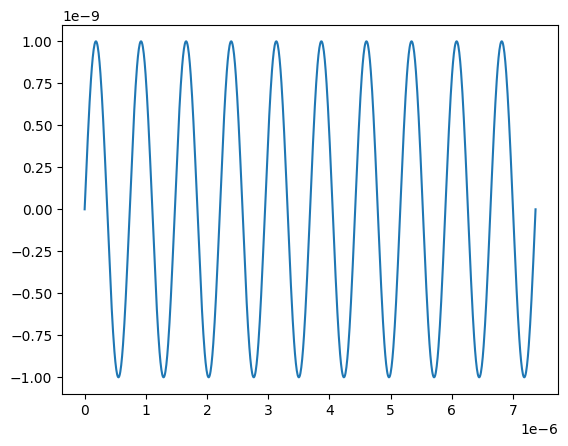

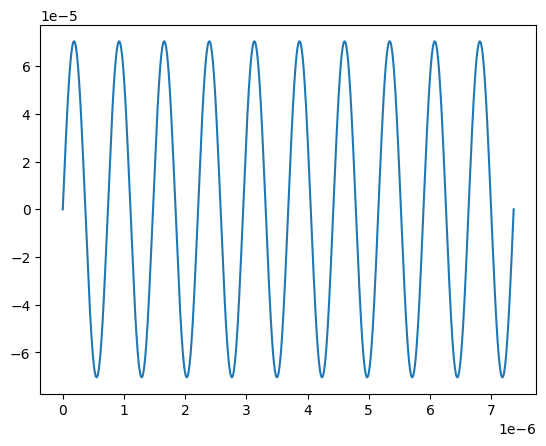

Bad pipe message: %s [b'\x8a+4I\x914\x18D\x08\xb4\x18\x1a9Z\xf3\xb1\x144\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00', b'A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2']
Bad pipe message: %s [b'\xb1R\x80\xcf]\xfd\x9a;\xc8\xfbiO\xb4\x0ev\x19\xcb\x86\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\

In [9]:
mux = 0
amp = 1e-9
muy = amp * jnp.sin((108000 * 2 * jnp.pi) * jnp.linspace(0, 10 / (108000), 1000))
mode = jnp.array([0, 1], dtype = jnp.int32)
waist = 1e-3
z = 0
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 1064e-9), 2))
targ_power = 200.0

r = 3e-3
gap = 1e-3 / 2
def diff(muy):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = muy) - x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = muy)

plt.plot(jnp.linspace(0, 5 / (108000 * 2 * jnp.pi), 1000), muy)
plt.show()

d = jax.vmap(diff)(muy)
plt.plot(jnp.linspace(0, 5 / (108000 * 2 * jnp.pi), 1000), d)